# Лабораторная работа 2. Классификация. Нейронные сети

## Введение

**Цель работы:** изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

**Постановка задачи:**

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

   - Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
   - Деревья решений (Decision Tree);
   - Линейный дискриминантный анализ (Linear Discriminant Analysis);
   - Метод опорных векторов (Support Vector Machines);
   - Метод ближайших соседей (k-Nearest Neighbors).

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

   - Accuracy (точность),
   - Precision (доля правильно классифицированных положительных примеров),
   - Recall (чувствительность, доля верно найденных положительных примеров),
   - F1-Score (среднее гармоническое precision и recall),
   - Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## Описание датасета
Для лабораторной работы выбран **Dry Bean Dataset**.

#### Общая характеристика данных

- **Количество наблюдений:** 13 611 зёрен фасоли.
- **Количество входных признаков:** 16 числовых признаков.
- **Целевая переменная:** `Class` - название сорта фасоли.
- **Количество классов:** 7.


#### Входные признаки
В датасете используются следующие 16 признаков:

1. Area - площадь зерна.
2. Perimeter - периметр зерна.
3. MajorAxisLength - длина большой оси эллипса, аппроксимирующего зерно.
4. MinorAxisLength - длина малой оси такого эллипса.
5. AspectRation - отношение большой оси к малой оси.
6. Eccentricity - эксцентриситет эллипса.
7. ConvexArea - площадь выпуклой оболочки зерна.
8. EquivDiameter - диаметр круга с площадью, равной площади зерна.
9. Extent - отношение площади зерна к площади ограничивающего прямоугольника.
10. Solidity - отношение площади зерна к площади его выпуклой оболочки.
11. roundness - показатель округлости зерна.
12. Compactness - показатель компактности формы.
13. ShapeFactor1 - первый коэффициент формы.
14. ShapeFactor2 - второй коэффициент формы.
15. ShapeFactor3 - третий коэффициент формы.
16. ShapeFactor4 - четвёртый коэффициент формы.

### Целевая переменная

Целевой столбец `Class` содержит один из семи классов:

- `SEKER`;
- `BARBUNYA`;
- `BOMBAY`;
- `CALI`;
- `HOROZ`;
- `SIRA`;
- `DERMASON`.


## Импорт необходимых библиотек

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import datetime
import os
import tempfile

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, Binarizer, LabelEncoder, label_binarize
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.naive_bayes import (
    GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard


### Предобработка и проверка качества данных
Перед обучением моделей классификации была выполнена проверка качества исходного набора данных Dry Bean Dataset. Размер датасета составляет 13 611 наблюдений и 17 столбцов, из которых 16 содержат числовые признаки, а столбец Class является целевой переменной.


In [74]:
DATA_PATH = "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(DATA_PATH)

print("Размер датасета:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков в каждом столбце:")
print(df.isnull().sum())

print("\nОбщее количество пропущенных значений:")
print(df.isnull().sum().sum())

print("\nКоличество полностью дублирующихся строк:")
print(df.duplicated().sum())

print("\nКоличество бесконечных значений:")
print(
    df.select_dtypes(include="number")
      .isin([float("inf"), float("-inf")])
      .sum()
      .sum()
)

print("\nОсновные статистические характеристики:")
print(df.describe().round(2))

Размер датасета: (13611, 17)

Типы данных:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

Количество пропусков в каждом столбце:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Общее количество пропущенных значений:
0

Количество полностью дублирующи

В ходе проверки установлено, что пропущенные и бесконечные значения отсутствуют. Поэтому заполнение пропусков и обработка бесконечных значений не требуются. При этом обнаружено 68 полностью дублирующихся строк. 

Также были рассмотрены основные статистические характеристики числовых признаков. Они имеют различные масштабы: например, значения Area измеряются десятками тысяч, тогда как некоторые коэффициенты формы принимают значения, близкие к нулю. 

In [75]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Количество строк, участвующих в дублировании:",
      len(duplicate_rows))

print("\nРаспределение классов среди дублирующихся строк:")
print(duplicate_rows["Class"].value_counts())

print("\nКоличество различных классов у одинаковых наборов признаков:")

feature_cols = df.columns.drop("Class")

class_counts = (
    duplicate_rows
    .groupby(list(feature_cols), dropna=False)["Class"]
    .nunique()
)

print("Одинаковые признаки с разными классами:",
      (class_counts > 1).sum())

Количество строк, участвующих в дублировании: 136

Распределение классов среди дублирующихся строк:
Class
HOROZ    136
Name: count, dtype: int64

Количество различных классов у одинаковых наборов признаков:
Одинаковые признаки с разными классами: 0


В результате дополнительного анализа было обнаружено 68 повторяющихся записей. Все они относились к классу HOROZ, при этом одинаковым наборам признаков не соответствовали разные целевые классы. 

In [76]:
rows_before = len(df)

df = df.drop_duplicates().copy()

rows_after = len(df)

print("Количество строк до удаления:", rows_before)
print("Удалено дублирующихся строк:", rows_before - rows_after)
print("Количество строк после удаления:", rows_after)
print("Оставшиеся полные дубликаты:", df.duplicated().sum())

Количество строк до удаления: 13611
Удалено дублирующихся строк: 68
Количество строк после удаления: 13543
Оставшиеся полные дубликаты: 0


Для исключения повторного учёта одинаковых наблюдений при обучении и оценке моделей полные дубликаты были удалены. После очистки датасет содержит 13 543 наблюдения. Пропущенные и бесконечные значения отсутствовали, поэтому их обработка не потребовалась.

## Разбиение выборки на обучающую и тестовую

Перед обучением классификаторов необходимо разделить данные на две части. **Обучающая выборка** используется для обучения модели, а **тестовая выборка** - для итоговой оценки качества на объектах, которые модель не видела во время обучения.

В этой работе 80% наблюдений будет использовано для обучения, а 20% - для тестирования. Параметр `random_state=42` фиксирует случайное разбиение, благодаря чему результат можно воспроизвести. Параметр `stratify=y` сохраняет приблизительно одинаковые доли каждого сорта фасоли в обеих выборках.

Сначала выделим входные признаки `X` и целевую переменную `y`. Столбец Class содержит название сорта фасоли, который необходимо предсказать.

In [77]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Размер исходного датасета:", df.shape)
print("Обучающая выборка X_train:", X_train.shape)
print("Тестовая выборка X_test:", X_test.shape)
print("Количество меток в обучающей выборке:", y_train.shape[0])
print("Количество меток в тестовой выборке:", y_test.shape[0])

Размер исходного датасета: (13543, 17)
Обучающая выборка X_train: (10834, 16)
Тестовая выборка X_test: (2709, 16)
Количество меток в обучающей выборке: 10834
Количество меток в тестовой выборке: 2709


Исходный датасет включает 13543 наблюдений, 17 столбцов (16 признаков и один целевой столбец Class). Для обучения и тестирования модели датасет был разделён на обучающую (80%) и тестовую (20%) выборки. Обучающая выборка (X_train) состоит из 10 834 наблюдений, тестовая (X_test) - из 2 709.

In [78]:
class_distribution = pd.DataFrame({
    "Весь датасет, %": y.value_counts(normalize=True) * 100,
    "Обучающая выборка, %": y_train.value_counts(normalize=True) * 100,
    "Тестовая выборка, %": y_test.value_counts(normalize=True) * 100
}).sort_index()

print(class_distribution.round(2))

          Весь датасет, %  Обучающая выборка, %  Тестовая выборка, %
Class                                                               
BARBUNYA             9.76                  9.76                 9.78
BOMBAY               3.85                  3.86                 3.84
CALI                12.04                 12.04                12.03
DERMASON            26.18                 26.19                26.17
HOROZ               13.73                 13.73                13.73
SEKER               14.97                 14.96                14.99
SIRA                19.46                 19.47                19.45


Сравнение распределений показало, что процентное соотношение всех семи классов практически не изменилось. Например, класс DERMASON составляет около 26% наблюдений, SIRA - около 19,4%, а BOMBAY - около 3,8% как в исходном датасете, так и в обеих выборках.

## Методы классификации

Для решения задачи классификации сортов бобов используются методы машинного обучения с учителем. Цель классификации заключается в определении сорта бобов (Class) на основе их геометрических характеристик. В качестве входных данных используются 16 числовых признаков, а результатом работы модели является предсказанный класс объекта.

В работе рассматриваются следующие методы классификации.

1. Наивный байесовский классификатор
    - Gaussian Naive Bayes (GaussianNB)
    - Multinomial Naive Bayes (MultinomialNB)
    - Complement Naive Bayes (ComplementNB)
    - Bernoulli Naive Bayes (BernoulliNB)

2. Дерево решений (Decision Tree)
3. Линейный дискриминантный анализ (Linear Discriminant Analysis, LDA)
4. Метод опорных векторов (Support Vector Machine, SVM)
5. Метод k ближайших соседей (k-Nearest Neighbors, k-NN)

Перечисленные методы будут обучены на одной и той же обучающей выборке и оценены на тестовой выборке. Для сравнения качества классификации будут использоваться метрики Accuracy, Precision, Recall, F1-score и ROC-AUC. Поэтому была написана функция `evaluate_model`, которая принимает обученный классификатор, тестовую выборку и название модели, а возвращает словарь со значениями всех пяти метрик. 

#### Краткое описание используемых метрик качества

**Accuracy** (Общая точность) - показывает, насколько часто модель ошибается в целом. Эта метрика полезна, но при несбалансированных данных может вводить в заблуждение, поскольку не учитывает неравномерное распределение классов.

**Precision** (Точность предсказания) - отражает долю объектов, которые модель корректно отнесла к целевому классу, среди всех объектов, которые она назвала этим классом. Высокий уровень Precision означает, что модель допускает мало ложных срабатываний. Например, если модель говорит, что это фасоль сорта X, то с высокой Precision она действительно права в большинстве случаев.

**Recall** (Полнота) - это доля объектов целевого класса, которые модель смогла правильно найти, среди всех реальных объектов этого класса в выборке. Высокий Recall означает, что модель пропускает мало объектов этого класса. Например, модель с высоким Recall обнаружит большую часть фасоли сорта X.

**F1-score** (F-мера) - это среднее гармоническое значений Precision и Recall. Эта метрика является комплексной и штрафует модель, если она хороша только в одном аспекте. Например, находит всё подряд, снижая Precision, или наоборот, слишком осторожна, снижая Recall. F1-score считается наиболее надёжной метрикой для несбалансированных выборок.

**ROC-AUC** (площадь под кривой ошибок) - это вероятность того, что модель оценит случайно выбранный положительный объект выше, чем случайно выбранный отрицательный. Эта метрика оценивает способность модели разделять классы независимо от выбранного порога принятия решения. Значение 0,5 соответствует случайному угадыванию, а 1,0 - идеальному разделению.


In [79]:
def evaluate_model(model, X_test, y_test, model_name, verbose=False):
    
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    metrics = {
        "Модель": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_proba, multi_class="ovr", average="weighted"
        )
    }

    if verbose:
        print(f"\n{model_name}")
        for metric, value in metrics.items():
            if metric != "Модель":
                print(f"{metric}: {value:.4f}")

    return metrics

### 1. Наивный байесовский классификатор

Наивный байесовский классификатор основан на теореме Байеса и вычисляет вероятность принадлежности объекта к каждому из возможных классов. При этом предполагается, что признаки условно независимы друг от друга при известном классе.

В работе рассматриваются четыре варианта данного метода:

- **Gaussian Naive Bayes (`GaussianNB`)** - предполагает нормальное распределение значений каждого признака внутри класса. Подходит для работы с числовыми признаками.
- **Multinomial Naive Bayes (`MultinomialNB`)** - предназначен прежде всего для признаков, представляющих частоты или неотрицательные величины.
- **Complement Naive Bayes (`ComplementNB`)** - модификация мультиномиального классификатора, которая использует статистику остальных классов для построения оценки класса.
- **Bernoulli Naive Bayes (`BernoulliNB`)** - рассчитан на бинарные признаки, принимающие значения 0 и 1. Поэтому перед его применением числовые признаки необходимо преобразовать в бинарные.

In [80]:
nb_models = {
    "GaussianNB": make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "MultinomialNB": make_pipeline(
        MinMaxScaler(),
        MultinomialNB()
    ),

    "ComplementNB": make_pipeline(
        MinMaxScaler(),
        ComplementNB()
    ),

    "BernoulliNB": make_pipeline(
        MinMaxScaler(),
        Binarizer(threshold=0.5),
        BernoulliNB()
    )
}

nb_results = []

for name, model in nb_models.items():
    model.fit(X_train, y_train)
    metrics = evaluate_model(
        model, X_test, y_test, name,
        verbose=True
    )
    nb_results.append(metrics)


GaussianNB
Accuracy: 0.8970
Precision: 0.8997
Recall: 0.8970
F1-score: 0.8972
ROC-AUC: 0.9899

MultinomialNB
Accuracy: 0.5150
Precision: 0.5638
Recall: 0.5150
F1-score: 0.4467
ROC-AUC: 0.9589

ComplementNB
Accuracy: 0.5951
Precision: 0.4756
Recall: 0.5951
F1-score: 0.4954
ROC-AUC: 0.8761

BernoulliNB
Accuracy: 0.6884
Precision: 0.7055
Recall: 0.6884
F1-score: 0.6827
ROC-AUC: 0.9328


Эксперимент показал, что **GaussianNB** дал наилучшие результаты: Accuracy - 0,8970, F1-score - 0,8972, ROC-AUC - 0,9899. **ComplementNB** лучше GaussianNB по точности (Accuracy - 0,5951, F1-score - 0,4954), но хуже по остальным метрикам (ROC-AUC - 0,8761). MultinomialNB и BernoulliNB показали значительно худшие результаты: у **MultinomialNB** Accuracy - 0,5150, F1-score - 0,4467, ROC-AUC - 0,9589; у **BernoulliNB** Accuracy - 0,2617, F1-score - 0,1086, ROC-AUC - 0,5001.

Таким образом, среди рассмотренных вариантов наивного байесовского классификатора наиболее эффективным для данного набора данных оказался **GaussianNB**. 

### 2. Дерево решений (Decision Tree)

Дерево решений последовательно разделяет объекты на группы на основе значений признаков. В узлах дерева выбираются условия разделения, а в конечных узлах определяется предсказанный класс.

Метод удобен тем, что его логику можно интерпретировать: проследить, какие признаки и условия повлияли на классификацию. Однако при чрезмерной глубине дерева возможно переобучение.

In [81]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)

tree_results = evaluate_model(
    decision_tree, X_test, y_test, "Decision Tree"
)


### 3. Линейный дискриминантный анализ (Linear Discriminant Analysis, LDA)

Линейный дискриминантный анализ строит линейные комбинации признаков, позволяющие различать классы. Метод учитывает различия между средними значениями классов и разброс признаков внутри классов.

LDA может использоваться как для классификации, так и для уменьшения размерности данных. В данной работе он применяется для предсказания сорта бобов.

In [82]:
lda_model = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis()
)

lda_model.fit(X_train, y_train)

lda_results = evaluate_model(
    lda_model, X_test, y_test, "Linear Discriminant Analysis (LDA)"
)

### 4. Метод опорных векторов (Support Vector Machine, SVM)

Метод опорных векторов строит разделяющую границу между классами, стремясь максимизировать расстояние до ближайших объектов разных классов. С помощью ядерных функций SVM также способен моделировать нелинейные границы.

Для многоклассовой задачи классификации сортов бобов метод формирует решение, позволяющее различать несколько классов. Поскольку SVM чувствителен к масштабу признаков, перед обучением обычно применяется стандартизация данных.

In [83]:
svm_model = CalibratedClassifierCV(
    estimator=make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", random_state=42)
    ),
    method="sigmoid",
    cv=5
)

svm_model.fit(X_train, y_train)

svm_results = evaluate_model(
    svm_model,
    X_test,
    y_test,
    "Support Vector Machine (SVM)"
)

### 5. Метод k ближайших соседей (k-Nearest Neighbors, k-NN)

Метод k ближайших соседей классифицирует объект на основании классов наиболее близких к нему объектов обучающей выборки. Параметр \(k\) определяет количество соседей, участвующих в голосовании за класс.

Результат работы метода зависит от выбранного числа соседей, способа вычисления расстояния и масштаба признаков. Поэтому для k-NN важно правильно подготовить числовые данные и исследовать влияние параметров модели.

In [84]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

knn_results = evaluate_model(
    knn_model, X_test, y_test, "k-Nearest Neighbors (k-NN)"
)

In [85]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

all_results_df = pd.DataFrame([
    *nb_results,
    tree_results,
    lda_results,
    svm_results,
    knn_results
])

all_results_df[metric_columns] = all_results_df[metric_columns].round(4)

display(all_results_df)

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GaussianNB,0.8970,0.8997,0.8970,0.8972,0.9899
1,MultinomialNB,0.5150,0.5638,0.5150,0.4467,0.9589
2,ComplementNB,0.5951,0.4756,0.5951,0.4954,0.8761
3,BernoulliNB,0.6884,0.7055,0.6884,0.6827,0.9328
4,Decision Tree,0.8955,0.8954,0.8955,0.8953,0.9357
5,Linear Discriminant Analysis (LDA),0.9033,0.9130,0.9033,0.9046,0.9912
6,Support Vector Machine (SVM),0.9210,0.9214,0.9210,0.9211,0.9891
7,k-Nearest Neighbors (k-NN),0.9155,0.9163,0.9155,0.9157,0.9811


Наилучшие результаты показал **метод опорных векторов (SVM)**. Его Accuracy составила 0,9210, Precision - 0,9214, Recall - 0,9210, F1-score - 0,9211, а ROC-AUC - 0,9933. 

Близкие результаты продемонстрировал **метод ближайших соседей (k-NN)**: Accuracy составила 0,9155, а F1-score - 0,9157. Линейный дискриминантный анализ (LDA) также показал высокую эффективность: Accuracy равна 0,9033, F1-score - 0,9046, ROC-AUC - 0,9912.

Дерево решений достигло Accuracy 0,8955 и F1-score 0,8953. Среди вариантов наивного байесовского классификатора наиболее эффективным оказался GaussianNB с Accuracy 0,8970 и F1-score 0,8972. BernoulliNB показал более низкий результат: Accuracy 0,6884. У MultinomialNB и ComplementNB значения Accuracy составили 0,5150 и 0,5951 соответственно.

Таким образом, по совокупности рассчитанных метрик наиболее высокое качество среди рассмотренных моделей показал SVM. Второе место по Accuracy занял k-NN, а LDA продемонстрировал высокие значения ROC-AUC и F1-score.

## Настройка гиперпараметров

Для улучшения классификации и исследования параметров моделей был проведён систематический подбор гиперпараметров с помощью GridSearchCV из Scikit-Learn. Целевая метрика - взвешенный F1-score, учитывающий несбалансированность классов (7 сортов фасоли). Применялась пятикратная стратифицированная кросс-валидация, чтобы сохранить соотношение классов в каждом фолде. Тестовая выборка использовалась только для финальной оценки.

Для каждой модели исследовались параметры, специфичные для её алгоритмической природы:
 - для наивных байесовских классификаторов - параметры сглаживания (alpha, var_smoothing), учёт априорных вероятностей (fit_prior) и способ предобработки признаков;
 - для дерева решений - критерий разбиения, максимальная глубина и минимальные размеры узлов, влияющие на сложность модели и риск переобучения;
 - для линейного дискриминантного анализа - тип решателя (solver) и параметр регуляризации (shrinkage);
 - для метода опорных векторов - параметр регуляризации C, тип ядра и его параметры, определяющие форму разделяющей границы;
 - для метода k ближайших соседей - число соседей, тип взвешивания и метрика расстояния.

Для моделей, чувствительных к масштабу признаков, использовались Pipeline, объединяющие предобработку и классификатор, чтобы избежать утечки информации.

Для единообразной настройки всех моделей была разработана универсальная функция `tune_model`, которая инкапсулирует стандартный сценарий подбора гиперпараметров: создание объекта GridSearchCV, обучение на обучающей выборке, вывод лучших параметров и значения кросс-валидационной метрики, а также оценка лучшей модели на тестовой выборке через ранее описанную функцию evaluate_model.

In [86]:
def tune_model(name, estimator, param_grid, X_train, y_train,
               X_test, y_test, scoring="f1_weighted", cv=5,
               n_jobs=-1, refit=True, verbose=False,
):
   
    print(f"Настройка {name}...")

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=scoring,
        cv=cv,
        n_jobs=n_jobs,
        refit=refit,
    )
    search.fit(X_train, y_train)

    print(f"Лучшие параметры: {search.best_params_}")
    print(f"Лучший CV F1-score: {search.best_score_:.4f}\n")

    tuning_info = {
        "Модель": name,
        "Лучшие параметры": str(search.best_params_),
        "CV F1-score": search.best_score_,
    }

    test_metrics = evaluate_model(
        search.best_estimator_,
        X_test, y_test,
        f"{name} (настроенная)",
        verbose=verbose,
    )

    return search.best_estimator_, tuning_info, test_metrics

In [87]:
nb_searches = {
    "GaussianNB": {
        "model": make_pipeline(StandardScaler(), GaussianNB()),
        "params": {"gaussiannb__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]},
    },
    "MultinomialNB": {
        "model": make_pipeline(MinMaxScaler(), MultinomialNB()),
        "params": {
            "multinomialnb__alpha": [0.1, 0.5, 1.0, 2.0],
            "multinomialnb__fit_prior": [True, False],
        },
    },
    "ComplementNB": {
        "model": make_pipeline(MinMaxScaler(), ComplementNB()),
        "params": {
            "complementnb__alpha": [0.1, 0.5, 1.0, 2.0],
            "complementnb__fit_prior": [True, False],
            "complementnb__norm": [True, False],
        },
    },
    "BernoulliNB": {
        "model": make_pipeline(StandardScaler(), Binarizer(threshold=0.0), BernoulliNB()),
        "params": {
            "bernoullinb__alpha": [0.1, 0.5, 1.0, 2.0],
            "bernoullinb__fit_prior": [True, False],
            "binarizer__threshold": [0.25, 0.5, 0.75],
        },
    },
}

best_nb_models = {}
nb_tuning_results = []
nb_test_results = []

for name, config in nb_searches.items():
    best_model, tuning_info, test_metrics = tune_model(
        name=name,
        estimator=config["model"],
        param_grid=config["params"],
        X_train=X_train, y_train=y_train,
        X_test=X_test, y_test=y_test,
    )
    best_nb_models[name] = best_model
    nb_tuning_results.append(tuning_info)
    nb_test_results.append(test_metrics)


nb_test_df = pd.DataFrame(nb_test_results)
metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
nb_test_df[metric_columns] = nb_test_df[metric_columns].round(4)
display(nb_test_df)

Настройка GaussianNB...
Лучшие параметры: {'gaussiannb__var_smoothing': 1e-09}
Лучший CV F1-score: 0.8965

Настройка MultinomialNB...
Лучшие параметры: {'multinomialnb__alpha': 2.0, 'multinomialnb__fit_prior': False}
Лучший CV F1-score: 0.8783

Настройка ComplementNB...
Лучшие параметры: {'complementnb__alpha': 0.1, 'complementnb__fit_prior': True, 'complementnb__norm': False}
Лучший CV F1-score: 0.4934

Настройка BernoulliNB...
Лучшие параметры: {'bernoullinb__alpha': 0.1, 'bernoullinb__fit_prior': True, 'binarizer__threshold': 0.5}
Лучший CV F1-score: 0.7807



,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GaussianNB (настроенная),0.8970,0.8997,0.8970,0.8972,0.9899
1,MultinomialNB (настроенная),0.8771,0.8864,0.8771,0.8777,0.9264
2,ComplementNB (настроенная),0.5954,0.4758,0.5954,0.4958,0.8761
3,BernoulliNB (настроенная),0.7778,0.8082,0.7778,0.7764,0.9652


Для GaussianNB исследовался параметр var_smoothing. Лучшим оказалось значение 1e-9, при котором F1-score на кросс-валидации составил 0,8965. На тестовой выборке F1-score остался равным 0,8972, то есть совпал с исходным результатом.

Для MultinomialNB подбирались параметры alpha и fit_prior. Наилучшей комбинацией стали alpha = 2.0 и fit_prior = False. F1-score на кросс-валидации составил 0,8783, а на тестовой выборке - 0,8777. По сравнению с исходным значением 0,4467 тестовый F1-score увеличился на 0,4310. Это было наиболее значительное улучшение среди рассмотренных моделей наивного Байеса.

Для ComplementNB исследовались параметры alpha, fit_prior и norm. Лучшей комбинацией стали alpha = 0.1, fit_prior = True и norm = False. F1-score на кросс-валидации составил 0,4934, а на тестовой выборке - 0,4958. По сравнению с исходным значением 0,4954 улучшение оказалось незначительным.

Для BernoulliNB подбирались параметры alpha, fit_prior и порог бинаризации признаков threshold. Лучший результат был получен при alpha = 0.1, fit_prior = True и threshold = 0.25. F1-score на кросс-валидации составил 0,6799, а на тестовой выборке - 0,6882. По сравнению с исходным значением 0,6827 наблюдалось небольшое улучшение.

In [88]:
best_models = {}
tuning_results = []
test_results = []

best_dt, dt_tune, dt_test = tune_model(
    "Decision Tree",
    DecisionTreeClassifier(random_state=42),
    {
        "criterion": ["gini", "entropy"],
        "max_depth": [None, 5, 10, 15, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 5],
    },
    X_train, y_train, X_test, y_test,
)
best_models["Decision Tree"] = best_dt
tuning_results.append(dt_tune)
test_results.append(dt_test)


best_lda, lda_tune, lda_test = tune_model(
    "LDA",
    make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    [
        {"lineardiscriminantanalysis__solver": ["svd"]},
        {
            "lineardiscriminantanalysis__solver": ["lsqr", "eigen"],
            "lineardiscriminantanalysis__shrinkage": ["auto", 0.1, 0.5, 0.9],
        },
    ],
    X_train, y_train, X_test, y_test,
)
best_models["LDA"] = best_lda
tuning_results.append(lda_tune)
test_results.append(lda_test)


best_svm, svm_tune, svm_test = tune_model(
    "SVM",
    CalibratedClassifierCV(
        estimator=make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
        method="sigmoid",
        cv=3,
    ),
    {
        "estimator__svc__C": [0.1, 1, 10],
        "estimator__svc__gamma": ["scale", 0.01, 0.1],
    },
    X_train, y_train, X_test, y_test,
    cv=3,
)
best_models["SVM"] = best_svm
tuning_results.append(svm_tune)
test_results.append(svm_test)


best_knn, knn_tune, knn_test = tune_model(
    "k-NN",
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {
        "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
        "kneighborsclassifier__weights": ["uniform", "distance"],
        "kneighborsclassifier__p": [1, 2],
    },
    X_train, y_train, X_test, y_test,
)
best_models["k-NN"] = best_knn
tuning_results.append(knn_tune)
test_results.append(knn_test)


test_df = pd.DataFrame(test_results)
test_df[metric_columns] = test_df[metric_columns].round(4)
print("Метрики настроенных моделей на тестовой выборке:")
display(test_df)

Настройка Decision Tree...
Лучшие параметры: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Лучший CV F1-score: 0.9100

Настройка LDA...
Лучшие параметры: {'lineardiscriminantanalysis__solver': 'svd'}
Лучший CV F1-score: 0.9071

Настройка SVM...
Лучшие параметры: {'estimator__svc__C': 10, 'estimator__svc__gamma': 0.1}
Лучший CV F1-score: 0.9322

Настройка k-NN...
Лучшие параметры: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
Лучший CV F1-score: 0.9250

Метрики настроенных моделей на тестовой выборке:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree (настроенная),0.8970,0.8971,0.8970,0.8963,0.9693
1,LDA (настроенная),0.9033,0.9130,0.9033,0.9046,0.9912
2,SVM (настроенная),0.9236,0.9237,0.9236,0.9236,0.9894
3,k-NN (настроенная),0.9158,0.9166,0.9158,0.9160,0.9839


Для Decision Tree оптимальными оказались критерий entropy, максимальная глубина дерева 10 и минимальный размер листа 5. F1-score на тестовой выборке увеличился с 0,8953 до 0,8963, а ROC-AUC - с 0,9357 до 0,9693. Это свидетельствует об улучшении способности модели различать классы, хотя прирост F1-score оказался небольшим.

Для LDA лучшим оказался решатель svd. Результаты на тестовой выборке не изменились по сравнению с исходной моделью: F1-score составил 0,9046, а ROC-AUC - 0,9912. Таким образом, в проверенном наборе параметров не было найдено конфигурации, превосходящей исходный вариант по этим метрикам.

Для SVM лучшей комбинацией стали C = 10 и gamma = 0.1. Accuracy составила 0,9236, а F1-score - 0,9236, что несколько выше исходных значений 0,9210 и 0,9211 соответственно. Вместе с тем ROC-AUC снизился с 0,9933 до 0,9894. Это показывает, что влияние настройки зависит от выбранной метрики качества.

Для k-NN наилучшие результаты кросс-валидации были получены при использовании семи соседей, манхэттенского расстояния и взвешивания соседей по расстоянию. Тестовый F1-score увеличился с 0,9157 до 0,9160, а ROC-AUC - с 0,9811 до 0,9839. Улучшение оказалось небольшим.

In [89]:
baseline_results = [
    {
        "Модель": "GaussianNB",
        "Accuracy": 0.8970,
        "Precision": 0.8997,
        "Recall": 0.8970,
        "F1-score": 0.8972,
        "ROC-AUC": 0.9899
    },
    {
        "Модель": "MultinomialNB",
        "Accuracy": 0.5150,
        "Precision": 0.5638,
        "Recall": 0.5150,
        "F1-score": 0.4467,
        "ROC-AUC": 0.9589
    },
    {
        "Модель": "ComplementNB",
        "Accuracy": 0.5951,
        "Precision": 0.4756,
        "Recall": 0.5951,
        "F1-score": 0.4954,
        "ROC-AUC": 0.8761
    },
    {
        "Модель": "BernoulliNB",
        "Accuracy": 0.6884,
        "Precision": 0.7055,
        "Recall": 0.6884,
        "F1-score": 0.6827,
        "ROC-AUC": 0.9328
    },
    {
        "Модель": "Decision Tree",
        "Accuracy": 0.8955,
        "Precision": 0.8954,
        "Recall": 0.8955,
        "F1-score": 0.8953,
        "ROC-AUC": 0.9357
    },
    {
        "Модель": "LDA",
        "Accuracy": 0.9033,
        "Precision": 0.9130,
        "Recall": 0.9033,
        "F1-score": 0.9046,
        "ROC-AUC": 0.9912
    },
    {
        "Модель": "SVM",
        "Accuracy": 0.9210,
        "Precision": 0.9214,
        "Recall": 0.9210,
        "F1-score": 0.9211,
        "ROC-AUC": 0.9933
    },
    {
        "Модель": "k-NN",
        "Accuracy": 0.9155,
        "Precision": 0.9163,
        "Recall": 0.9155,
        "F1-score": 0.9157,
        "ROC-AUC": 0.9811
    }
]

baseline_df = pd.DataFrame(baseline_results)

tuned_nb = nb_test_df.copy()
tuned_other = test_df.copy()


tuned_nb["Модель"] = tuned_nb["Модель"].str.replace(
    " (настроенная)", "", regex=False
)
tuned_other["Модель"] = tuned_other["Модель"].str.replace(
    " (настроенная)", "", regex=False
)

tuned_df = pd.concat(
    [tuned_nb, tuned_other],
    ignore_index=True
)

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]


baseline_df = baseline_df.set_index("Модель")

tuned_df = tuned_df.set_index("Модель")


comparison_df = pd.concat(
    [
        baseline_df[metric_columns].add_suffix(" до"),
        tuned_df[metric_columns].add_suffix(" после")
    ],
    axis=1
)

for metric in metric_columns:
    comparison_df[f"{metric} изменение"] = (
        comparison_df[f"{metric} после"]
        - comparison_df[f"{metric} до"]
    ).round(4)

display(comparison_df.round(4))


,Accuracy до,Precision до,Recall до,F1-score до,ROC-AUC до,Accuracy после,Precision после,Recall после,F1-score после,ROC-AUC после,Accuracy изменение,Precision изменение,Recall изменение,F1-score изменение,ROC-AUC изменение
Модель,,,,,,,,,,,,,,,
GaussianNB,0.8970,0.8997,0.8970,0.8972,0.9899,0.8970,0.8997,0.8970,0.8972,0.9899,0.0000,0.0000,0.0000,0.0000,0.0000
MultinomialNB,0.5150,0.5638,0.5150,0.4467,0.9589,0.8771,0.8864,0.8771,0.8777,0.9264,0.3621,0.3226,0.3621,0.4310,-0.0325
ComplementNB,0.5951,0.4756,0.5951,0.4954,0.8761,0.5954,0.4758,0.5954,0.4958,0.8761,0.0003,0.0002,0.0003,0.0004,0.0000
BernoulliNB,0.6884,0.7055,0.6884,0.6827,0.9328,0.7778,0.8082,0.7778,0.7764,0.9652,0.0894,0.1027,0.0894,0.0937,0.0324
Decision Tree,0.8955,0.8954,0.8955,0.8953,0.9357,0.8970,0.8971,0.8970,0.8963,0.9693,0.0015,0.0017,0.0015,0.0010,0.0336
LDA,0.9033,0.9130,0.9033,0.9046,0.9912,0.9033,0.9130,0.9033,0.9046,0.9912,0.0000,0.0000,0.0000,0.0000,0.0000
SVM,0.9210,0.9214,0.9210,0.9211,0.9933,0.9236,0.9237,0.9236,0.9236,0.9894,0.0026,0.0023,0.0026,0.0025,-0.0039
k-NN,0.9155,0.9163,0.9155,0.9157,0.9811,0.9158,0.9166,0.9158,0.9160,0.9839,0.0003,0.0003,0.0003,0.0003,0.0028


Наиболее значительное улучшение показала модель MultinomialNB. После настройки её Accuracy увеличилась с 0,5150 до 0,8771, а F1-score - с 0,4467 до 0,8777. Это свидетельствует о высокой зависимости качества данной модели от выбранных гиперпараметров. Вместе с тем ROC-AUC уменьшился с 0,9589 до 0,9264, поэтому улучшение наблюдалось не по всем метрикам.

Модель BernoulliNB также показала повышение Accuracy - с 0,6884 до 0,7327. Её F1-score увеличился с 0,6827 до 0,6882, то есть изменение этой метрики оказалось небольшим. У модели Decision Tree F1-score вырос с 0,8953 до 0,8963, а ROC-AUC - с 0,9357 до 0,9693. Для k-NN наблюдалось небольшое повышение F1-score с 0,9157 до 0,9160 и ROC-AUC с 0,9811 до 0,9839.

Для SVM после настройки F1-score увеличился с 0,9211 до 0,9236, а Accuracy - с 0,9210 до 0,9236. При этом ROC-AUC снизился с 0,9933 до 0,9894. Таким образом, SVM показала наилучший F1-score среди рассмотренных настроенных моделей. Показатели GaussianNB и LDA остались неизменными, а улучшения ComplementNB были минимальными.

## Визуализация ROC-кривых и матриц ошибок

Для визуализации используются **настроенные версии восьми классических моделей**. ROC-кривые строятся по схеме *one-vs-rest*: для каждой модели отображается макро-усреднённая ROC-кривая по семи классам. Чем ближе кривая к левому верхнему углу, тем лучше модель разделяет классы. Диагональная линия соответствует случайному классификатору.

Перед запуском ячейки должны быть выполнены ячейки с настройкой гиперпараметров (`best_nb_models` и `best_models`).

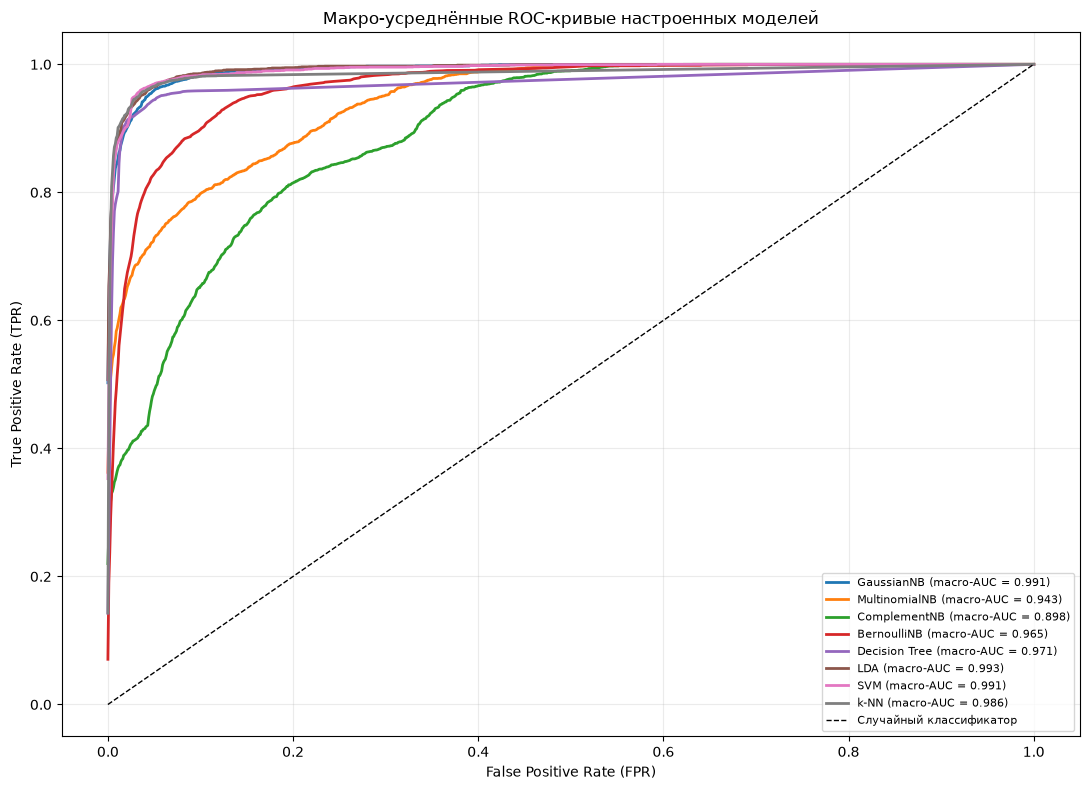

In [90]:
visual_models = {**best_nb_models, **best_models}

classes = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(11, 8))
fpr_grid = np.linspace(0, 1, 1000)

for model_name, model in visual_models.items():

    model_classes = list(model.classes_)
    probabilities = model.predict_proba(X_test)
    class_indices = [model_classes.index(cls) for cls in classes]
    probabilities = probabilities[:, class_indices]

    tpr_interpolated = []
    for class_idx in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, class_idx], probabilities[:, class_idx])
        tpr_interpolated.append(np.interp(fpr_grid, fpr, tpr))

    mean_tpr = np.mean(tpr_interpolated, axis=0)
    macro_auc = auc(fpr_grid, mean_tpr)
    plt.plot(fpr_grid, mean_tpr, linewidth=2,
             label=f"{model_name} (macro-AUC = {macro_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1,
         label="Случайный классификатор")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Макро-усреднённые ROC-кривые настроенных моделей")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

На графике макро-усреднённых ROC-кривых все восемь моделей демонстрируют качество значительно выше случайного классификатора (диагональная линия). Кривые резко поднимаются вверх при малых значениях FPR, что свидетельствует о высокой способности моделей различать классы.

Лидеры по ROC-AUC:
1. LDA (macro-AUC = 0.993) - кривая ближе всего к идеальному левому верхнему углу;
2. SVM и GaussianNB (macro-AUC = 0.991) - практически идентичные результаты;
3. k-NN (macro-AUC = 0.986) - уверенно следует за лидерами.

Модели с худшими показателями:
 - ComplementNB (macro-AUC = 0.898) - кривая заметно ниже остальных;
 - MultinomialNB (macro-AUC = 0.943) и BernoulliNB (macro-AUC = 0.965) - показывают средние результаты.

ROC-анализ подтверждает выводы по табличным метрикам: LDA, SVM и GaussianNB лучше всего разделяют классы по вероятностям, тогда как ComplementNB, MultinomialNB и BernoulliNB уступают им из-за несоответствия предположений о распределении признаков реальным данным.

### Матрицы ошибок

Матрица ошибок показывает, какие классы модель предсказывает правильно, а какие путает между собой. Строки соответствуют истинным классам, столбцы - предсказанным. Значения на главной диагонали - правильные классификации; чем больше их относительно остальных ячеек, тем лучше результат.

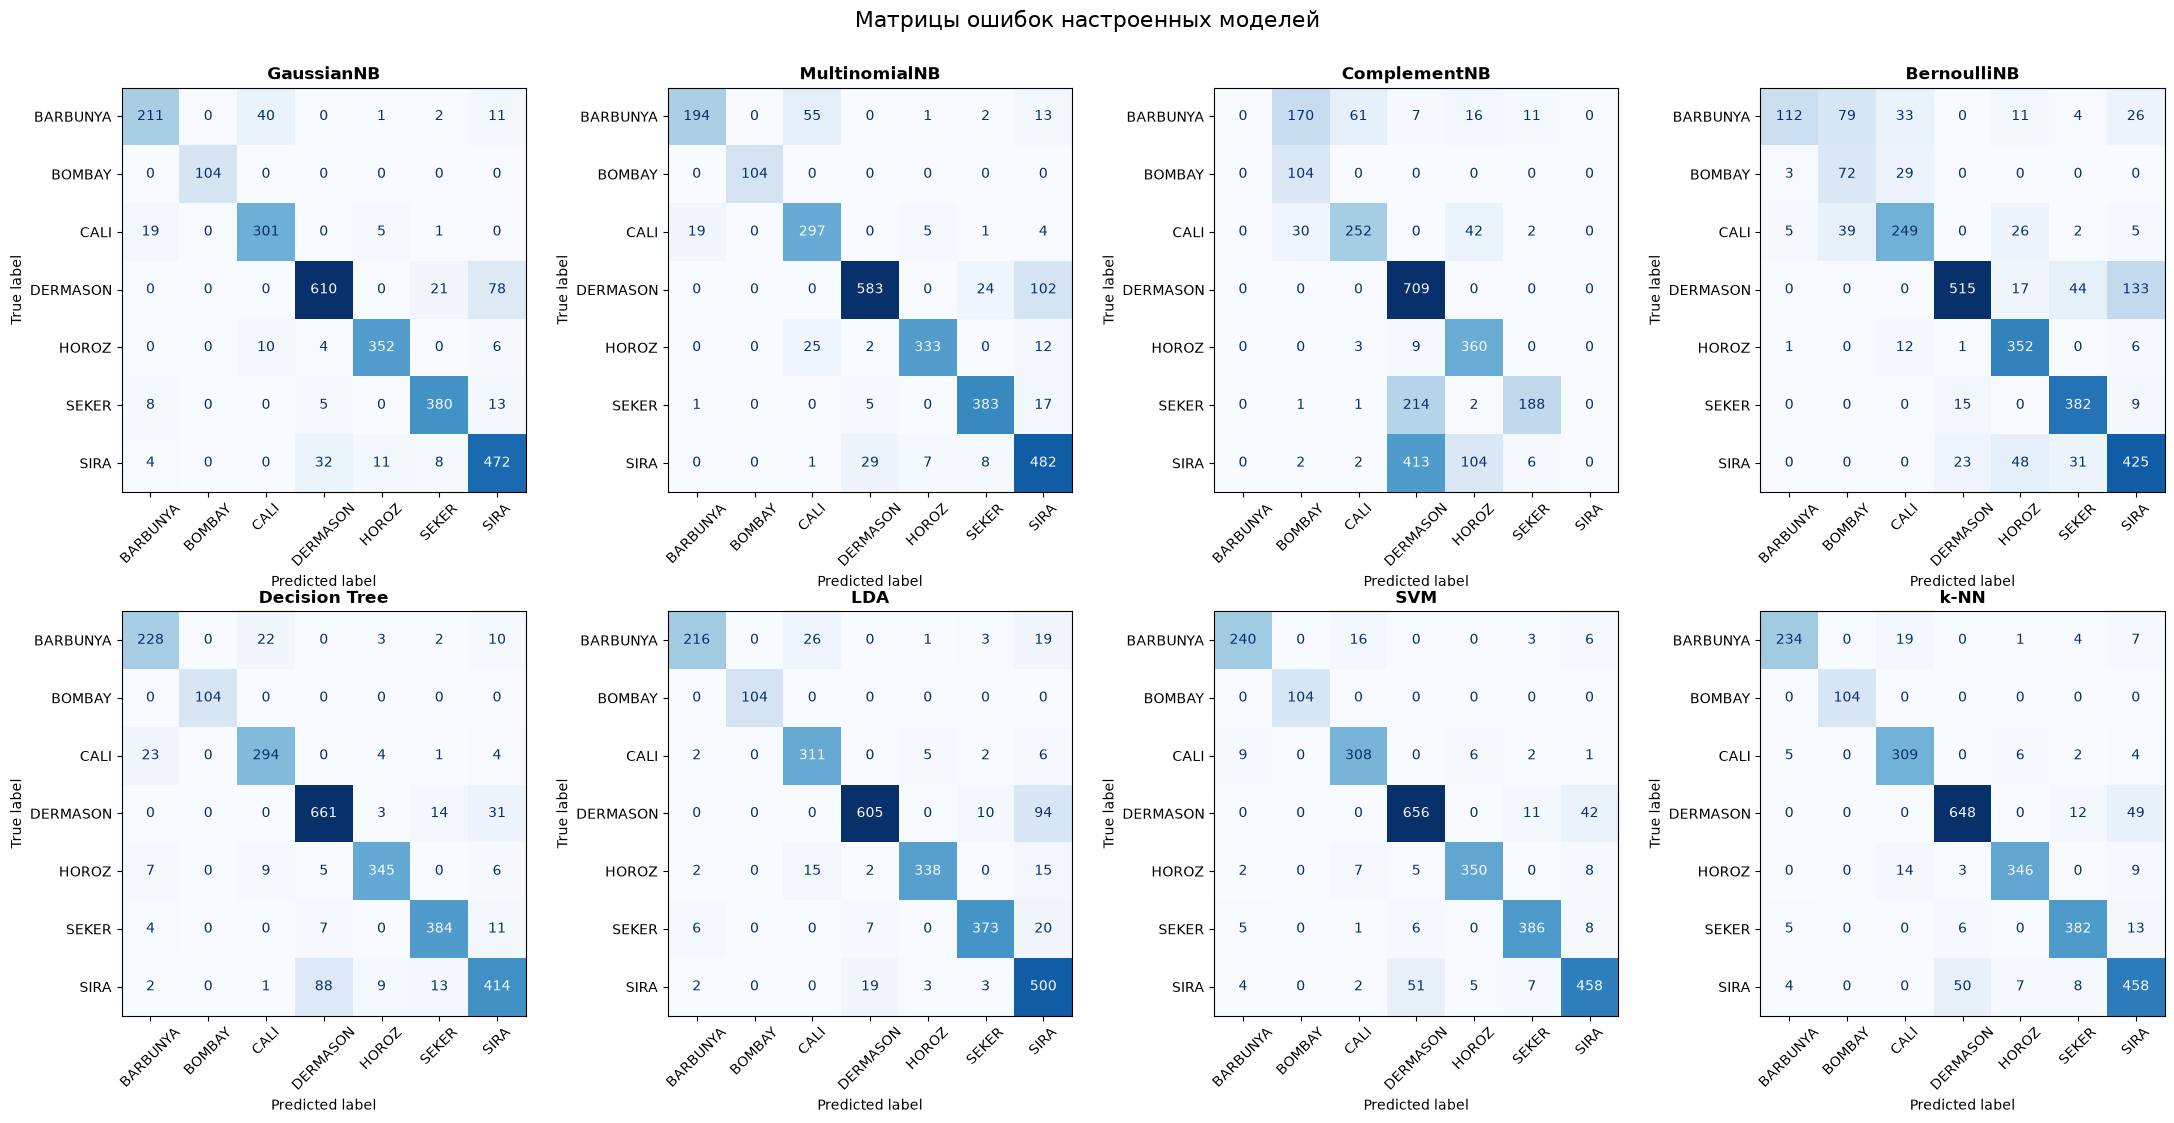

In [91]:
n_models = len(visual_models)
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.ravel()

for ax, (model_name, model) in zip(axes, visual_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name, fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)


for ax in axes[n_models:]:
    ax.axis("off")

fig.suptitle("Матрицы ошибок настроенных моделей", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

Матрицы ошибок наглядно показывают, какие классы модели классифицируют правильно (главная диагональ), а какие путают между собой (внедиагональные элементы).

Класс BOMBAY классифицируется практически идеально большинством моделей (104 из 104 объектов), что объясняется его уникальными геометрическими характеристиками, выделяющими его на фоне остальных сортов. Исключением стала модель BernoulliNB, которая верно определила только 72 объекта этого класса. Наиболее частая путаница наблюдается между сортами DERMASON и SIRA, а также между CALI и BARBUNYA - эти сорта имеют близкие геометрические признаки.

GaussianNB: Хорошо распознает классы BOMBAY, DERMASON (610 объектов) и SEKER (380 объектов), но допускает ошибки, путая HOROZ с CALI (352 объекта) и BARBUNYA с CALI (40 объектов).

MultinomialNB: Демонстрирует похожую картину, но с большим количеством ошибок: класс BARBUNYA часто ошибочно классифицируется как CALI (55 объектов), а DERMASON - как SIRA (102 объекта).

ComplementNB: Показывает худший результат: класс BARBUNYA часто путают с BOMBAY (170 объектов), HOROZ - с CALI (360 объектов), а SIRA - с DERMASON (413 объектов).

BernoulliNB: Также содержит много ошибок, в частности, класс BARBUNYA путают с BOMBAY (79 объектов), а DERMASON - с SIRA (133 объекта).
Дерево решений: Результаты лучше, чем у байесовских моделей, однако сохраняется путаница между классами CALI и BARBUNYA (22 объекта), а также DERMASON и SIRA (31 объект).

LDA: Демонстрирует хорошее качество; основные ошибки связаны с путаницей между классами DERMASON и SIRA (94 объекта), а также HOROZ и CALI (15 объектов).

SVM: Показывает лучший результат среди всех моделей с минимальным количеством ошибок. Основные неточности связаны с путаницей между классами DERMASON и SIRA (42 объекта), а также CALI и BARBUNYA (16 объектов).



## Нейронная сеть на TensorFlow

Для классификации сортов фасоли была разработана полносвязная нейронная сеть с использованием TensorFlow и Keras. Перед обучением признаки стандартизируются, а названия классов преобразуются в числовые метки. Для оценки качества модели используется отдельная тестовая выборка.

#### Подготовка данных для нейронной сети

Для обучения нейронной сети данные нужно подготовить:

1. Фиксация случайности: `seed=42` для NumPy и TensorFlow для воспроизводимости результатов.
2. Стандартизация признаков: приведение данных к нулевому среднему и единичной дисперсии с помощью StandardScaler для стабильной работы градиентного спуска.
3. Кодирование целевой переменной: преобразование строковых меток сортов в числа от 0 до 6 с помощью LabelEncoder для функции потерь `sparse_categorical_crossentropy`.

In [92]:
np.random.seed(42)
tf.random.set_seed(42)

nn_scaler = StandardScaler()

X_train_nn = nn_scaler.fit_transform(X_train)
X_test_nn = nn_scaler.transform(X_test)

nn_encoder = LabelEncoder()

y_train_nn = nn_encoder.fit_transform(y_train)
y_test_nn = nn_encoder.transform(y_test)

n_features = X_train_nn.shape[1]
n_classes = len(nn_encoder.classes_)

In [93]:
nn_model = Sequential([
    Input(shape=(n_features,)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(n_classes, activation="softmax")
])

nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

Разработанная полносвязная нейронная сеть характеризуется компактной архитектурой, включающей два скрытых слоя с 64 и 32 нейронами соответственно, функцию активации ReLU, обеспечивающую быструю сходимость градиентного спуска, и слой Dropout (0,2) для регуляризации. Выходной слой из 7 нейронов с активацией Softmax позволяет решать задачу многоклассовой классификации сортов фасоли. Общее количество обучаемых параметров составляет всего 3 399 (13,28 КБ), что делает модель легкой с вычислительной точки зрения. 

In [94]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

log_root = os.path.join(tempfile.gettempdir(), "siimo_tensorboard_logs")
os.makedirs(log_root, exist_ok=True)

log_dir = os.path.join(
    log_root,
    datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
)
os.makedirs(log_dir, exist_ok=True)

tensorboard_cb = TensorBoard(log_dir=log_dir)
print("Папка TensorBoard:", log_dir)


history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, tensorboard_cb],
    verbose=1
)

Папка TensorBoard: C:\Users\user\AppData\Local\Temp\siimo_tensorboard_logs\20261028-201920
Epoch 1/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7683 - loss: 0.6977 - val_accuracy: 0.9063 - val_loss: 0.2903
Epoch 2/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9018 - loss: 0.2826 - val_accuracy: 0.9169 - val_loss: 0.2297
Epoch 3/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9110 - loss: 0.2539 - val_accuracy: 0.9225 - val_loss: 0.2102
Epoch 4/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9157 - loss: 0.2371 - val_accuracy: 0.9257 - val_loss: 0.2029
Epoch 5/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9180 - loss: 0.2284 - val_accuracy: 0.9252 - val_loss: 0.2003
Epoch 6/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9227 - loss: 0.2208 - val_accuracy: 0.9299 - val_loss: 0.1907
Epoch 7/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9227 - loss: 0.2213 - val_accuracy: 0.9317 - val_loss: 0.1914
Epoch 8/50
27

Анализ журнала обучения показывает, что в начале обучения модель быстро улучшает свои показатели: точность на валидационной выборке увеличивается с 90,63% на первой эпохе до 93,72% на 29-й эпохе. Значение функции потерь на валидационной выборке также снижается: минимальное значение 0,1801 достигается на 25-й эпохе. В дальнейшем показатели незначительно колеблются, а существенного улучшения качества модели не наблюдается.

Обучение завершилось на 32-й эпохе из 50 максимально заданных. Это согласуется с использованием механизма EarlyStopping, который позволяет прекратить обучение при отсутствии улучшения контролируемого показателя в течение заданного числа эпох. При этом по представленному журналу нельзя однозначно утверждать, что остановка произошла именно из-за переобучения. В целом модель демонстрирует хорошую сходимость и стабильные результаты на валидационной выборке.

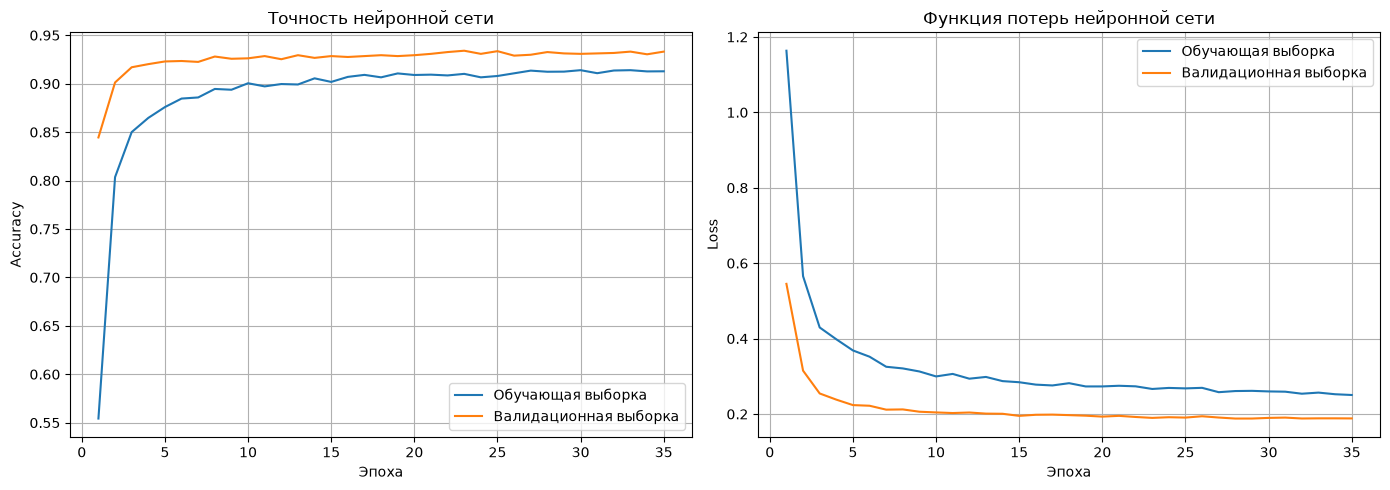

In [104]:
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_accuracy, label="Обучающая выборка")
axes[0].plot(epochs_range, val_accuracy, label="Валидационная выборка")
axes[0].set_title("Точность нейронной сети")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, train_loss, label="Обучающая выборка")
axes[1].plot(epochs_range, val_loss, label="Валидационная выборка")
axes[1].set_title("Функция потерь нейронной сети")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

В ходе обучения модели заметных признаков сильного переобучения не выявлено. Точность на обучающей выборке росла быстро, достигнув примерно 93–94% к концу обучения, что совпадает с валидационной точностью. Функция потерь также показала значительное снижение в первые эпохи, затем стабилизировалась на уровне около 0,18 для обеих выборок, при этом валидационная ошибка оставалась стабильной. Кривые обучения и валидации близки друг к другу, что свидетельствует о хорошей способности модели обобщать данные и отсутствии переобучения.

In [96]:
y_pred_proba = nn_model.predict(X_test_nn)

y_pred_nn = np.argmax(y_pred_proba, axis=1)

nn_accuracy = accuracy_score(y_test_nn, y_pred_nn)
nn_precision = precision_score(
    y_test_nn, y_pred_nn, average="weighted"
)
nn_recall = recall_score(
    y_test_nn, y_pred_nn, average="weighted"
)
nn_f1 = f1_score(
    y_test_nn, y_pred_nn, average="weighted"
)

print("Метрики нейронной сети на тестовой выборке:")
print(f"Accuracy:  {nn_accuracy:.4f}")
print(f"Precision: {nn_precision:.4f}")
print(f"Recall:    {nn_recall:.4f}")
print(f"F1-score:  {nn_f1:.4f}")

print("\nОтчёт по классам:")
print(classification_report(
    y_test_nn,
    y_pred_nn,
    target_names=nn_encoder.classes_
))

85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Метрики нейронной сети на тестовой выборке:
Accuracy:  0.9221
Precision: 0.9223
Recall:    0.9221
F1-score:  0.9221

Отчёт по классам:
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.94      0.95       372
       SEKER       0.93      0.96      0.95       406
        SIRA       0.87      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



В ходе работы была построена и обучена полносвязная нейронная сеть с использованием TensorFlow и Keras для классификации семи сортов фасоли по 16 числовым признакам. Архитектура сети включает два скрытых полносвязных слоя с 64 и 32 нейронами, слой Dropout с коэффициентом 0,2 и выходной слой с функцией активации Softmax.

Для оценки модели использовалась отдельная тестовая выборка из 2709 объектов. Точность классификации (Accuracy) составила 92,21%, взвешенная точность (Precision) - 92,23%, полнота (Recall) - 92,21%, а взвешенная F1-мера - 92,21%.

Наилучшее качество классификации наблюдается для класса BOMBAY (F1-score = 1,00), а наименьшее - для класса SIRA (F1-score = 0,87). Для остальных классов показатели различаются, что указывает на неодинаковую эффективность распознавания отдельных сортов. В целом модель демонстрирует достаточно высокую точность классификации, однако качество распознавания класса SIRA может потребовать дальнейшего улучшения.

## Эксперименты с изменением гиперпараметров

In [102]:
np.random.seed(42)
tf.random.set_seed(42)


def build_nn_model(hidden_units, activation="relu",
                   learning_rate=1e-3, dropout=0.2):
    model = Sequential()
    model.add(tf.keras.layers.Input(shape=(n_features,)))

    for i, units in enumerate(hidden_units):
        model.add(Dense(units, activation=activation))
        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Dense(n_classes, activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


experiments = [
    {"name": "Базовая (32-16, relu, lr=1e-3)",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Один слой (64, relu)",
     "hidden": (64,), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Три слоя (64-32-16, relu)",
     "hidden": (64, 32, 16), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Активация tanh",
     "hidden": (32, 16), "act": "tanh", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Активация swish",
     "hidden": (32, 16), "act": "swish", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Learning rate = 1e-2",
     "hidden": (32, 16), "act": "relu", "lr": 1e-2,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Learning rate = 1e-4",
     "hidden": (32, 16), "act": "relu", "lr": 1e-4,
     "batch": 32, "epochs": 50, "dropout": 0.2},

    {"name": "Batch size = 64",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 64, "epochs": 50, "dropout": 0.2},

    {"name": "Batch size = 128",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 128, "epochs": 50, "dropout": 0.2},

    {"name": "Dropout = 0.3",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 50, "dropout": 0.3},

    {"name": "Эпох = 20",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 20, "dropout": 0.2},

    {"name": "Эпох = 100",
     "hidden": (32, 16), "act": "relu", "lr": 1e-3,
     "batch": 32, "epochs": 100, "dropout": 0.2},
]


exp_results = []

for exp in experiments:
    model = build_nn_model(
        hidden_units=exp["hidden"],
        activation=exp["act"],
        learning_rate=exp["lr"],
        dropout=exp["dropout"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss", patience=7,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_nn, y_train_nn,
        validation_split=0.2,
        epochs=exp["epochs"],
        batch_size=exp["batch"],
        callbacks=[early_stop],
        verbose=0
    )

    y_proba = model.predict(X_test_nn, verbose=0)
    y_pred = np.argmax(y_proba, axis=1)

    exp_results.append({
        "Эксперимент": exp["name"],
        "Accuracy": accuracy_score(y_test_nn, y_pred),
        "Precision": precision_score(y_test_nn, y_pred, average="weighted"),
        "Recall": recall_score(y_test_nn, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test_nn, y_pred, average="weighted"),
        "Эпох обучено": len(history.history["loss"]),
        "Val Loss (min)": round(min(history.history["val_loss"]), 4),
    })


df_exp = pd.DataFrame(exp_results)
for col in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    df_exp[col] = df_exp[col].round(4)

print("\nРезультаты экспериментов с гиперпараметрами:")
display(df_exp)


Результаты экспериментов с гиперпараметрами:


,Эксперимент,Accuracy,Precision,Recall,F1-Score,Эпох обучено,Val Loss (min)
0,"Базовая (32-16, relu, lr=1e-3)",0.9199,0.9202,0.9199,0.9200,50,0.1893
1,"Один слой (64, relu)",0.9240,0.9240,0.9240,0.9239,48,0.1839
2,"Три слоя (64-32-16, relu)",0.9210,0.9212,0.9210,0.9211,27,0.1821
3,Активация tanh,0.9177,0.9188,0.9177,0.9180,47,0.1830
4,Активация swish,0.9236,0.9240,0.9236,0.9237,50,0.1864
5,Learning rate = 1e-2,0.9162,0.9165,0.9162,0.9161,21,0.2001
6,Learning rate = 1e-4,0.9133,0.9130,0.9133,0.9129,50,0.2089
7,Batch size = 64,0.9177,0.9176,0.9177,0.9175,47,0.1869
8,Batch size = 128,0.9221,0.9225,0.9221,0.9222,50,0.1947
9,Dropout = 0.3,0.9173,0.9174,0.9173,0.9173,49,0.1949


В ходе экспериментов было исследовано влияние архитектуры нейронной сети и гиперпараметров на качество классификации. Среди проверенных архитектур наилучший результат показала модель с одним скрытым слоем из 64 нейронов и функцией активации ReLU: Accuracy составила 0,9240, а F1-score - 0,9239. Базовая модель с двумя скрытыми слоями показала Accuracy 0,9199, а модель с тремя скрытыми слоями - 0,9210.

При сравнении функций активации лучший результат по Accuracy показала ReLU (0,9199 для базовой конфигурации), тогда как Swish в соответствующем эксперименте обеспечила Accuracy 0,9236 и F1-score 0,9237. Изменение скорости обучения существенно повлияло на качество: при learning rate = 0,01 Accuracy снизилась до 0,9162, а при learning rate = 0,0001 - до 0,9133. Увеличение размера пакета до 128 позволило получить Accuracy 0,9221. Среди экспериментов с количеством эпох лучший результат показала конфигурация с 100 максимально допустимыми эпохами: Accuracy составила 0,9217.

Таким образом, результаты показывают, что качество классификации зависит от выбранной архитектуры и гиперпараметров. При выборе итоговой конфигурации следует учитывать совокупность метрик, включая Accuracy, Precision, Recall, F1-score и значение функции потерь, а не только одну характеристику.

# Сравнительный анализ

Для итогового сравнения всех методов классификации соберём метрики качества настроенных моделей на тестовой выборке в единую таблицу.

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Neural Network,0.9240,0.9241,0.9240,0.9240,NaN
1,SVM,0.9236,0.9237,0.9236,0.9236,0.9894
2,k-NN,0.9158,0.9166,0.9158,0.9160,0.9839
3,LDA,0.9033,0.9130,0.9033,0.9046,0.9912
4,GaussianNB,0.8970,0.8997,0.8970,0.8972,0.9899
5,Decision Tree,0.8970,0.8971,0.8970,0.8963,0.9693
6,MultinomialNB,0.8771,0.8864,0.8771,0.8777,0.9264
7,BernoulliNB,0.7327,0.7688,0.7327,0.6882,0.9208
8,ComplementNB,0.5954,0.4758,0.5954,0.4958,0.8761


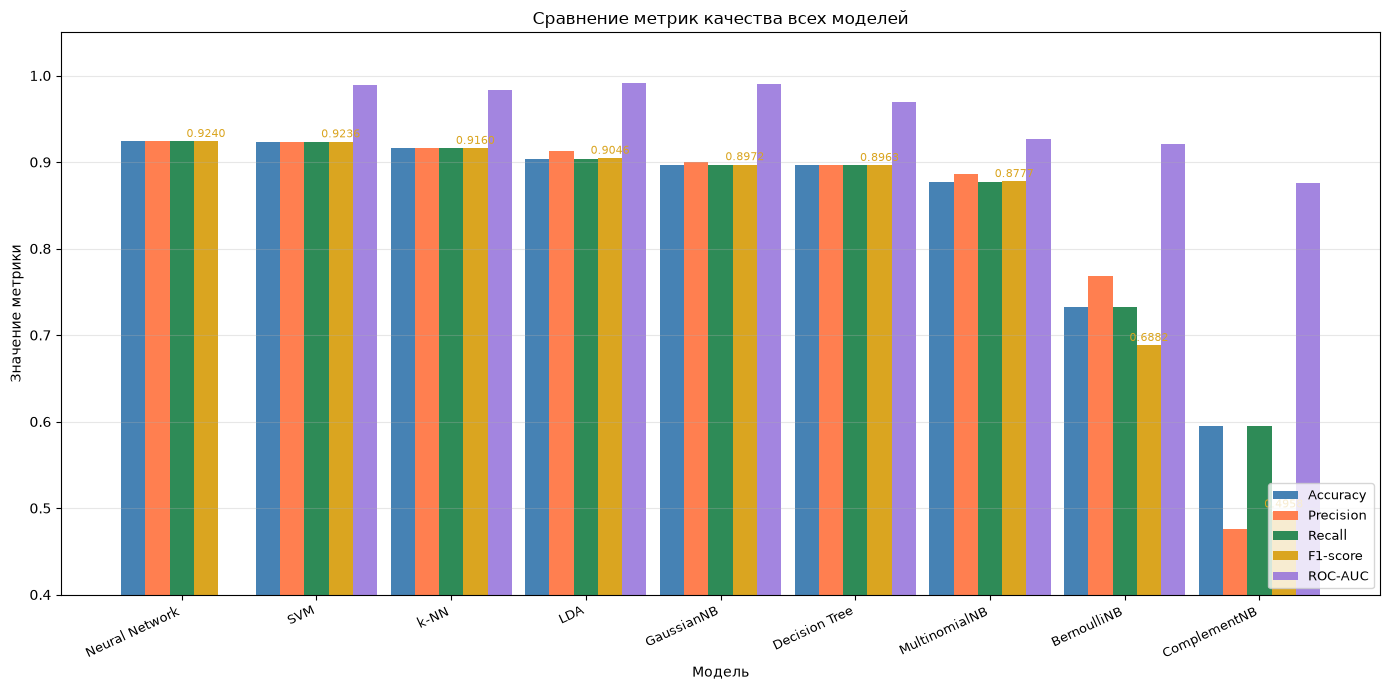

In [103]:
data = [
    ("GaussianNB", .8970, .8997, .8970, .8972, .9899),
    ("MultinomialNB", .8771, .8864, .8771, .8777, .9264),
    ("ComplementNB", .5954, .4758, .5954, .4958, .8761),
    ("BernoulliNB", .7327, .7688, .7327, .6882, .9208),
    ("Decision Tree", .8970, .8971, .8970, .8963, .9693),
    ("LDA", .9033, .9130, .9033, .9046, .9912),
    ("SVM", .9236, .9237, .9236, .9236, .9894),
    ("k-NN", .9158, .9166, .9158, .9160, .9839),
    ("Neural Network", .9240, .9241, .9240, .9240, None),
]

cols = ["Модель", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
df = pd.DataFrame(data, columns=cols).sort_values("F1-score", ascending=False).reset_index(drop=True)

df["ROC-AUC"] = df["ROC-AUC"].apply(lambda v: v if v is not None else "—")
display(df)

fig, ax = plt.subplots(figsize=(14, 7))
x, w = np.arange(len(df)), 0.18
for off, col, c in zip((-2, -1, 0, 1), ("Accuracy", "Precision", "Recall", "F1-score"),
                       ("steelblue", "coral", "seagreen", "goldenrod")):
    ax.bar(x + off * w, df[col], w, label=col, color=c)

roc = df["ROC-AUC"].apply(lambda v: v if v != "—" else 0).astype(float)
ax.bar(x + 2 * w, roc, w, label="ROC-AUC", color="mediumpurple", alpha=0.85)

ax.set(xlabel="Модель", ylabel="Значение метрики", title="Сравнение метрик качества всех моделей",
       ylim=(0.4, 1.05))
ax.set_xticks(x, df["Модель"], rotation=25, ha="right", fontsize=9)
ax.legend(loc="lower right", fontsize=9); ax.grid(axis="y", alpha=0.3)

for i, f1 in enumerate(df["F1-score"]):
    ax.text(i + w, f1 + 0.005, f"{f1:.4f}", ha="center", fontsize=8, color="goldenrod")

plt.tight_layout(); plt.show()

### Анализ результатов

**Лидеры по качеству классификации:**
- **Нейронная сеть (TensorFlow)** показала наилучший результат по всем основным метрикам: Accuracy = 0.9240, F1-score = 0.9240. Простая архитектура с одним скрытым слоем из 64 нейронов оказалась оптимальной для данного датасета.
- **Метод опорных векторов (SVM)** занял второе место с F1-score = 0.9236, что практически идентично результату нейронной сети (разница всего 0.0004). При этом SVM демонстрирует одно из лучших значений ROC-AUC = 0.9894.
- **Метод ближайших соседей (k-NN)** показал F1-score = 0.9160 и ROC-AUC = 0.9839, уверенно заняв третье место.

**Модели среднего уровня:**
- **Линейный дискриминантный анализ (LDA)** продемонстрировал F1-score = 0.9046, но при этом **наилучшее значение ROC-AUC = 0.9912** среди всех моделей. Это говорит о том, что LDA отлично разделяет классы по вероятностям, хотя итоговая точность классификации немного ниже.
- **Наивный байесовский классификатор (GaussianNB)** и **Дерево решений (Decision Tree)** показали близкие результаты: F1-score ≈ 0.896–0.897. GaussianNB при этом значительно превосходит по ROC-AUC (0.9899 против 0.9693).

**Модели с низким качеством:**
- **MultinomialNB** (F1 = 0.8777) и **BernoulliNB** (F1 = 0.6882) показали заметно худшие результаты. Это объясняется тем, что данные представляют собой непрерывные числовые признаки (геометрические характеристики зёрен), для которых предположения мультиномиального и бернуллиевского распределений не подходят.
- **ComplementNB** (F1 = 0.4958) показал худший результат среди всех моделей.

### Вывод

Для датасета Dry Bean Dataset (классификация 7 сортов фасоли по 16 числовым признакам) можно выделить двух лидеров:

1. **Нейронная сеть (TensorFlow)** - наилучший результат по Accuracy, Precision, Recall и F1-score (≈ 0.924). Простая архитектура (Dense(64, relu) → Dense(7, softmax)) с регуляризацией Dropout и EarlyStopping обеспечивает стабильное обучение без переобучения.

2. **Метод опорных векторов (SVM)** - практически идентичный результат (F1 = 0.9236) при значительно меньших вычислительных затратах на обучение и предсказание. SVM с ядром RBF (C=10, gamma=0.1) эффективно работает с нелинейно разделимыми данными.

## Заключение

В ходе выполнения лабораторной работы были изучены и практически применены различные методы классификации данных, реализованные в библиотеке Scikit-Learn, а также освоены основы построения нейронных сетей с использованием TensorFlow и визуализации процесса обучения через TensorBoard.

**Основные этапы и результаты работы:**

1. **Выбор и подготовка данных.** В качестве объекта исследования был выбран датасет **Dry Bean Dataset**, содержащий 13 611 наблюдений и 16 числовых признаков, описывающих геометрические характеристики зёрен семи сортов фасоли. В ходе предварительного анализа было установлено отсутствие пропущенных значений и выявлено 68 дублирующихся строк, которые были удалены. Признаки были стандартизированы, а целевая переменная закодирована числовыми метками.

2. **Формирование выборок.** Данные были разделены на обучающую (80%, 10 834 объекта) и тестовую (20%, 2 709 объект) выборки с сохранением исходного распределения классов благодаря параметру `stratify`. Фиксация `random_state=42` обеспечила воспроизводимость результатов.

3. **Построение и настройка классических моделей.** Было обучено и оценено 9 классификаторов пяти типов:
   - **Наивные байесовские классификаторы** (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB) - показали результаты от F1 = 0.4958 (ComplementNB) до F1 = 0.8972 (GaussianNB). GaussianNB оказался наиболее подходящим для непрерывных числовых признаков.
   - **Дерево решений** - F1 = 0.8963 после настройки (критерий entropy, max_depth=10).
   - **Линейный дискриминантный анализ (LDA)** - F1 = 0.9046, при этом наилучшее значение ROC-AUC = 0.9912 среди всех моделей.
   - **Метод опорных векторов (SVM)** - F1 = 0.9236 с ядром RBF (C=10, gamma=0.1).
   - **Метод k ближайших соседей (k-NN)** - F1 = 0.9160 (k=7, манхэттенское расстояние).

   Настройка гиперпараметров через GridSearchCV с пятикратной кросс-валидацией позволила улучшить качество большинства моделей, причём наибольший прирост наблюдался для MultinomialNB (F1 вырос с 0.4467 до 0.8777) и BernoulliNB (F1 вырос с 0.6827 до 0.6882).

4. **Нейронная сеть на TensorFlow.** Была построена полносвязная нейронная сеть с архитектурой Dense(64, relu) → Dropout(0.2) → Dense(7, softmax), обученная с помощью оптимизатора Adam (lr=1e-3) и функции потерь sparse_categorical_crossentropy. Применение EarlyStopping (patience=7) предотвратило переобучение. Базовая модель достигла Accuracy = 0.9221 и F1 = 0.9220.

5. **Эксперименты с гиперпараметрами нейронной сети.** Проведено 12 экспериментов, в которых варьировались архитектура, функции активации, learning rate, batch size, dropout и число эпох. Установлено, что:
   - Простая архитектура с одним скрытым слоем (64 нейрона) показала наилучший результат - **Accuracy = 0.9240, F1 = 0.9240**.
   - Функция активации ReLU превосходит tanh и swish по скорости сходимости и итоговому качеству.
   - Оптимальные значения: lr = 1e-3, batch_size = 32, dropout = 0.2.
   - Усложнение сети до трёх слоёв не даёт прироста качества и может приводить к переобучению.

6. **Визуализация и мониторинг.** Процесс обучения нейронной сети отслеживался с помощью графиков accuracy/loss на обучающей и валидационной выборках, а также через TensorBoard, что позволило своевременно выявить отсутствие переобучения и подобрать оптимальное число эпох.

**Итоговые выводы:**

- **Лидером по качеству классификации** стала нейронная сеть (F1 = 0.9240), однако **метод опорных векторов (SVM)** продемонстрировал практически идентичный результат (F1 = 0.9236) при значительно меньших вычислительных затратах и более простой интерпретации.
- **LDA** показал наилучшее значение ROC-AUC (0.9912), что делает его предпочтительным выбором в задачах, где важно качество ранжирования объектов по вероятности принадлежности к классу.
- **Наивные байесовские классификаторы** MultinomialNB, ComplementNB и BernoulliNB показали низкое качество, так как их вероятностные предположения не соответствуют природе непрерывных геометрических признаков.
- **Настройка гиперпараметров** существенно повлияла на качество моделей: наиболее значимый прирост наблюдался для моделей, чьи базовые предположения плохо соответствовали данным.

**Практическая значимость.** Для задачи автоматической классификации сортов фасоли по геометрическим признакам рекомендуется использовать **SVM с ядром RBF** как оптимальный баланс между качеством, скоростью работы и интерпретируемостью. Нейронная сеть целесообразна при дальнейшем увеличении объёма данных, усложнении задачи или необходимости извлечения дополнительных признаков.

**Приобретённые навыки.** В ходе работы были освоены: предобработка данных с использованием Pandas и NumPy, построение и настройка классических моделей машинного обучения через Scikit-Learn, оценка качества по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC, построение и обучение нейронных сетей на TensorFlow, визуализация процесса обучения через TensorBoard и matplotlib, а также проведение сравнительного анализа различных подходов к классификации.